# Figure 2 — mOU versus sparse DCM
Run the cells in order to reproduce the nine-panel paper figure: best subject, worst subject, and group mean. Uses the saved mOU matrices and TR1 DCM matrices (`A`); no model fitting or atlas/font downloads.

The original 62-ROI comparison, DCM threshold |A| ≥ 0.01, plotting functions, panel order, colors, font, and figure dimensions are retained. Subject IDs are matched explicitly to DCM filenames. The saved mOU row order is reconstructed from the sorted paired HCP cohort defined in the original notebook and checked against its array length. Outputs: `Figures/figure_2.jpg` and `Figures/figure_2.pdf`.


In [2]:
from pathlib import Path
from collections import OrderedDict
import re, string
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import cm, font_manager as fm
from scipy.io import loadmat
from scipy.stats import linregress
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

PROJECT = Path.home() / 'Scripts/Insight_project'
DATA = PROJECT / 'numpy files'
OUTPUT = PROJECT / 'Figures'
OUTPUT.mkdir(exist_ok=True)
BOLD_ROOT = Path.home() / 'hcp_parcellated'
DCM_ROOT = Path.home() / 'codici/results'
font_file = PROJECT / 'Notebook figure/Avenir-Oblique.ttf'
fm.fontManager.addfont(font_file)
plt.rcParams['font.family'] = fm.FontProperties(fname=font_file).get_name()

def dediag(matrix):
    matrix = np.array(matrix, copy=True)
    np.fill_diagonal(matrix, 0)
    return matrix


## Load and align subjects
The original mOU array contains the paired REST1/REST2 cohort in sorted subject-ID order. Only matching DCM files with a 62 × 62 `A` matrix are included. DCM is transposed to the row-source orientation of the saved mOU matrices.

In [4]:
JS = np.load(DATA / 'EC_matrix_HCP1_74.npy', mmap_mode='r')
cohort_ids = []
for folder in sorted(BOLD_ROOT.iterdir()):
    files = [folder / f'{folder.name}_REST{k}_LR_Schaefer100+AAL.npy' for k in (1, 2)]
    if all(f.is_file() and np.load(f, mmap_mode='r').shape[0] == 1200 for f in files):
        cohort_ids.append(folder.name)
assert len(cohort_ids) == JS.shape[0] == 1013, 'Original cohort ordering cannot be reconstructed.'
row_for_subject = {sid: i for i, sid in enumerate(cohort_ids)}
subject_ids, indices, matrices = [], [], []
for file in sorted(DCM_ROOT.glob('sub-*.mat_TR1_realData_var11_emo_points16.mat')):
    match = re.fullmatch(r'sub-(\d+)\.mat_TR1_realData_var11_emo_points16\.mat', file.name)
    if match is None or match[1] not in row_for_subject:
        continue
    A = np.asarray(loadmat(file)['A'], dtype=float)
    if A.shape != (62, 62):
        continue
    if not np.isfinite(A).all():
        raise ValueError(f'Non-finite DCM matrix: {file}')
    subject_ids.append(match[1])
    indices.append(row_for_subject[match[1]])
    matrices.append(A)
assert matrices and len(set(subject_ids)) == len(subject_ids)
indici = np.asarray(indices, dtype=int)
ec_dcm = np.stack(matrices)
assert np.isfinite(JS[indici, :62, :62]).all()
print(f'Matched subjects: {len(subject_ids)}; cortical ROIs: 62')


Matched subjects: 144; cortical ROIs: 62


In [5]:
# Same atlas labels and clustering used in the original notebook, loaded locally.
table = nib.load(PROJECT / 'Schaefer2018_100Parcels_7Networks_order.dlabel.nii').header.get_axis(0).label[0]
labels = np.array([table[i][0] for i in range(1, 101)])
mapping = loadmat(PROJECT / 'clust_idx_LEMON.mat')['clust_idx_LEMON'].reshape(-1)[:100]
assert np.array_equal(np.unique(mapping), np.arange(1, 63))
new_lab = [str(np.unique(labels[mapping == k])[0])[10:] for k in range(1, 63)]
assert all(label.startswith(('LH_', 'RH_')) for label in new_lab)
def plot_fc_matrix(fc, labels, ax, cmap='bwr', vmin=-0.2, vmax=0.2, fontsize=13, pos=7, plot_emi_x=True, plot_emi_y=True):

    def parse_label(lab):
        return (lab.split('_')[0], lab.split('_')[1])
    groups = OrderedDict()
    for i, lab in enumerate(labels):
        hemi, net = parse_label(lab)
        groups.setdefault(f'{hemi}_{net}', []).append(i)
    new_order, bounds, names = ([], [], [])
    start = 0
    for key, idxs in groups.items():
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end
    fc_ord = fc[np.ix_(new_order, new_order)]
    n = fc_ord.shape[0]
    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax)
    ticks = [0] + [end for _, end in bounds]
    ax.set_xticks(np.array(ticks) - 0.5)
    ax.set_yticks(np.array(ticks) - 0.5)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(axis='x', bottom=True, labelbottom=True)
    for t in ticks:
        ax.axhline(t - 0.5, color='black', linewidth=0.2)
        ax.axvline(t - 0.5, color='black', linewidth=0.2)
    lh_count = sum((lab.startswith('LH_') for lab in labels))
    ax.axhline(lh_count - 0.5, color='black', linewidth=0.5)
    ax.axvline(lh_count - 0.5, color='black', linewidth=0.5)
    for (start, end), name in zip(bounds, names):
        center = (start + end) / 2
        hemi, net = name.split('_')
        ax.text(center - 0.5, n + 1, f'{net}', ha='center', va='top', rotation=70, clip_on=False, fontsize=fontsize)
        ax.text(-1, center - 0.5, f'{net}', ha='right', va='center', clip_on=False, fontsize=fontsize)
        ax.set_xlim(-0.5, n - 0.5)
        ax.set_ylim(n - 0.5, -0.5)
    lh_center = lh_count / 2
    rh_center = lh_count + (n - lh_count) / 2
    offset_x = n + 1
    offset_y = -1
    if plot_emi_x:
        ax.text(lh_center, offset_x + pos, 'LH', ha='center', va='top', fontweight='bold', clip_on=False, fontsize=20)
        ax.text(rh_center, offset_x + pos, 'RH', ha='center', va='top', fontweight='bold', clip_on=False, fontsize=20)
    if plot_emi_y:
        ax.text(offset_y - pos, lh_center, 'LH', ha='right', va='center', fontweight='bold', clip_on=False, fontsize=20)
        ax.text(offset_y - pos, rh_center, 'RH', ha='right', va='center', fontweight='bold', clip_on=False, fontsize=20)
    return im

## Paper figure
Correlations and regression use entries above the original DCM magnitude threshold; diagonals are zeroed for display and excluded by this threshold. Histograms use the same matched subjects. Group matrices are averaged over that same cohort.

108
108
BEST: 82 0.88
WORST: 108 0.69
Best subject: 123117 r = 0.8765980679662927
Worst subject: 130720 r = 0.6917290562642536
Mean / 5th / 95th percentile: 0.8163077872864858 0.7689305101456829 0.856658748407833
Saved: /home/benedetta/Scripts/Insight_project/Figures/figure_2.jpg


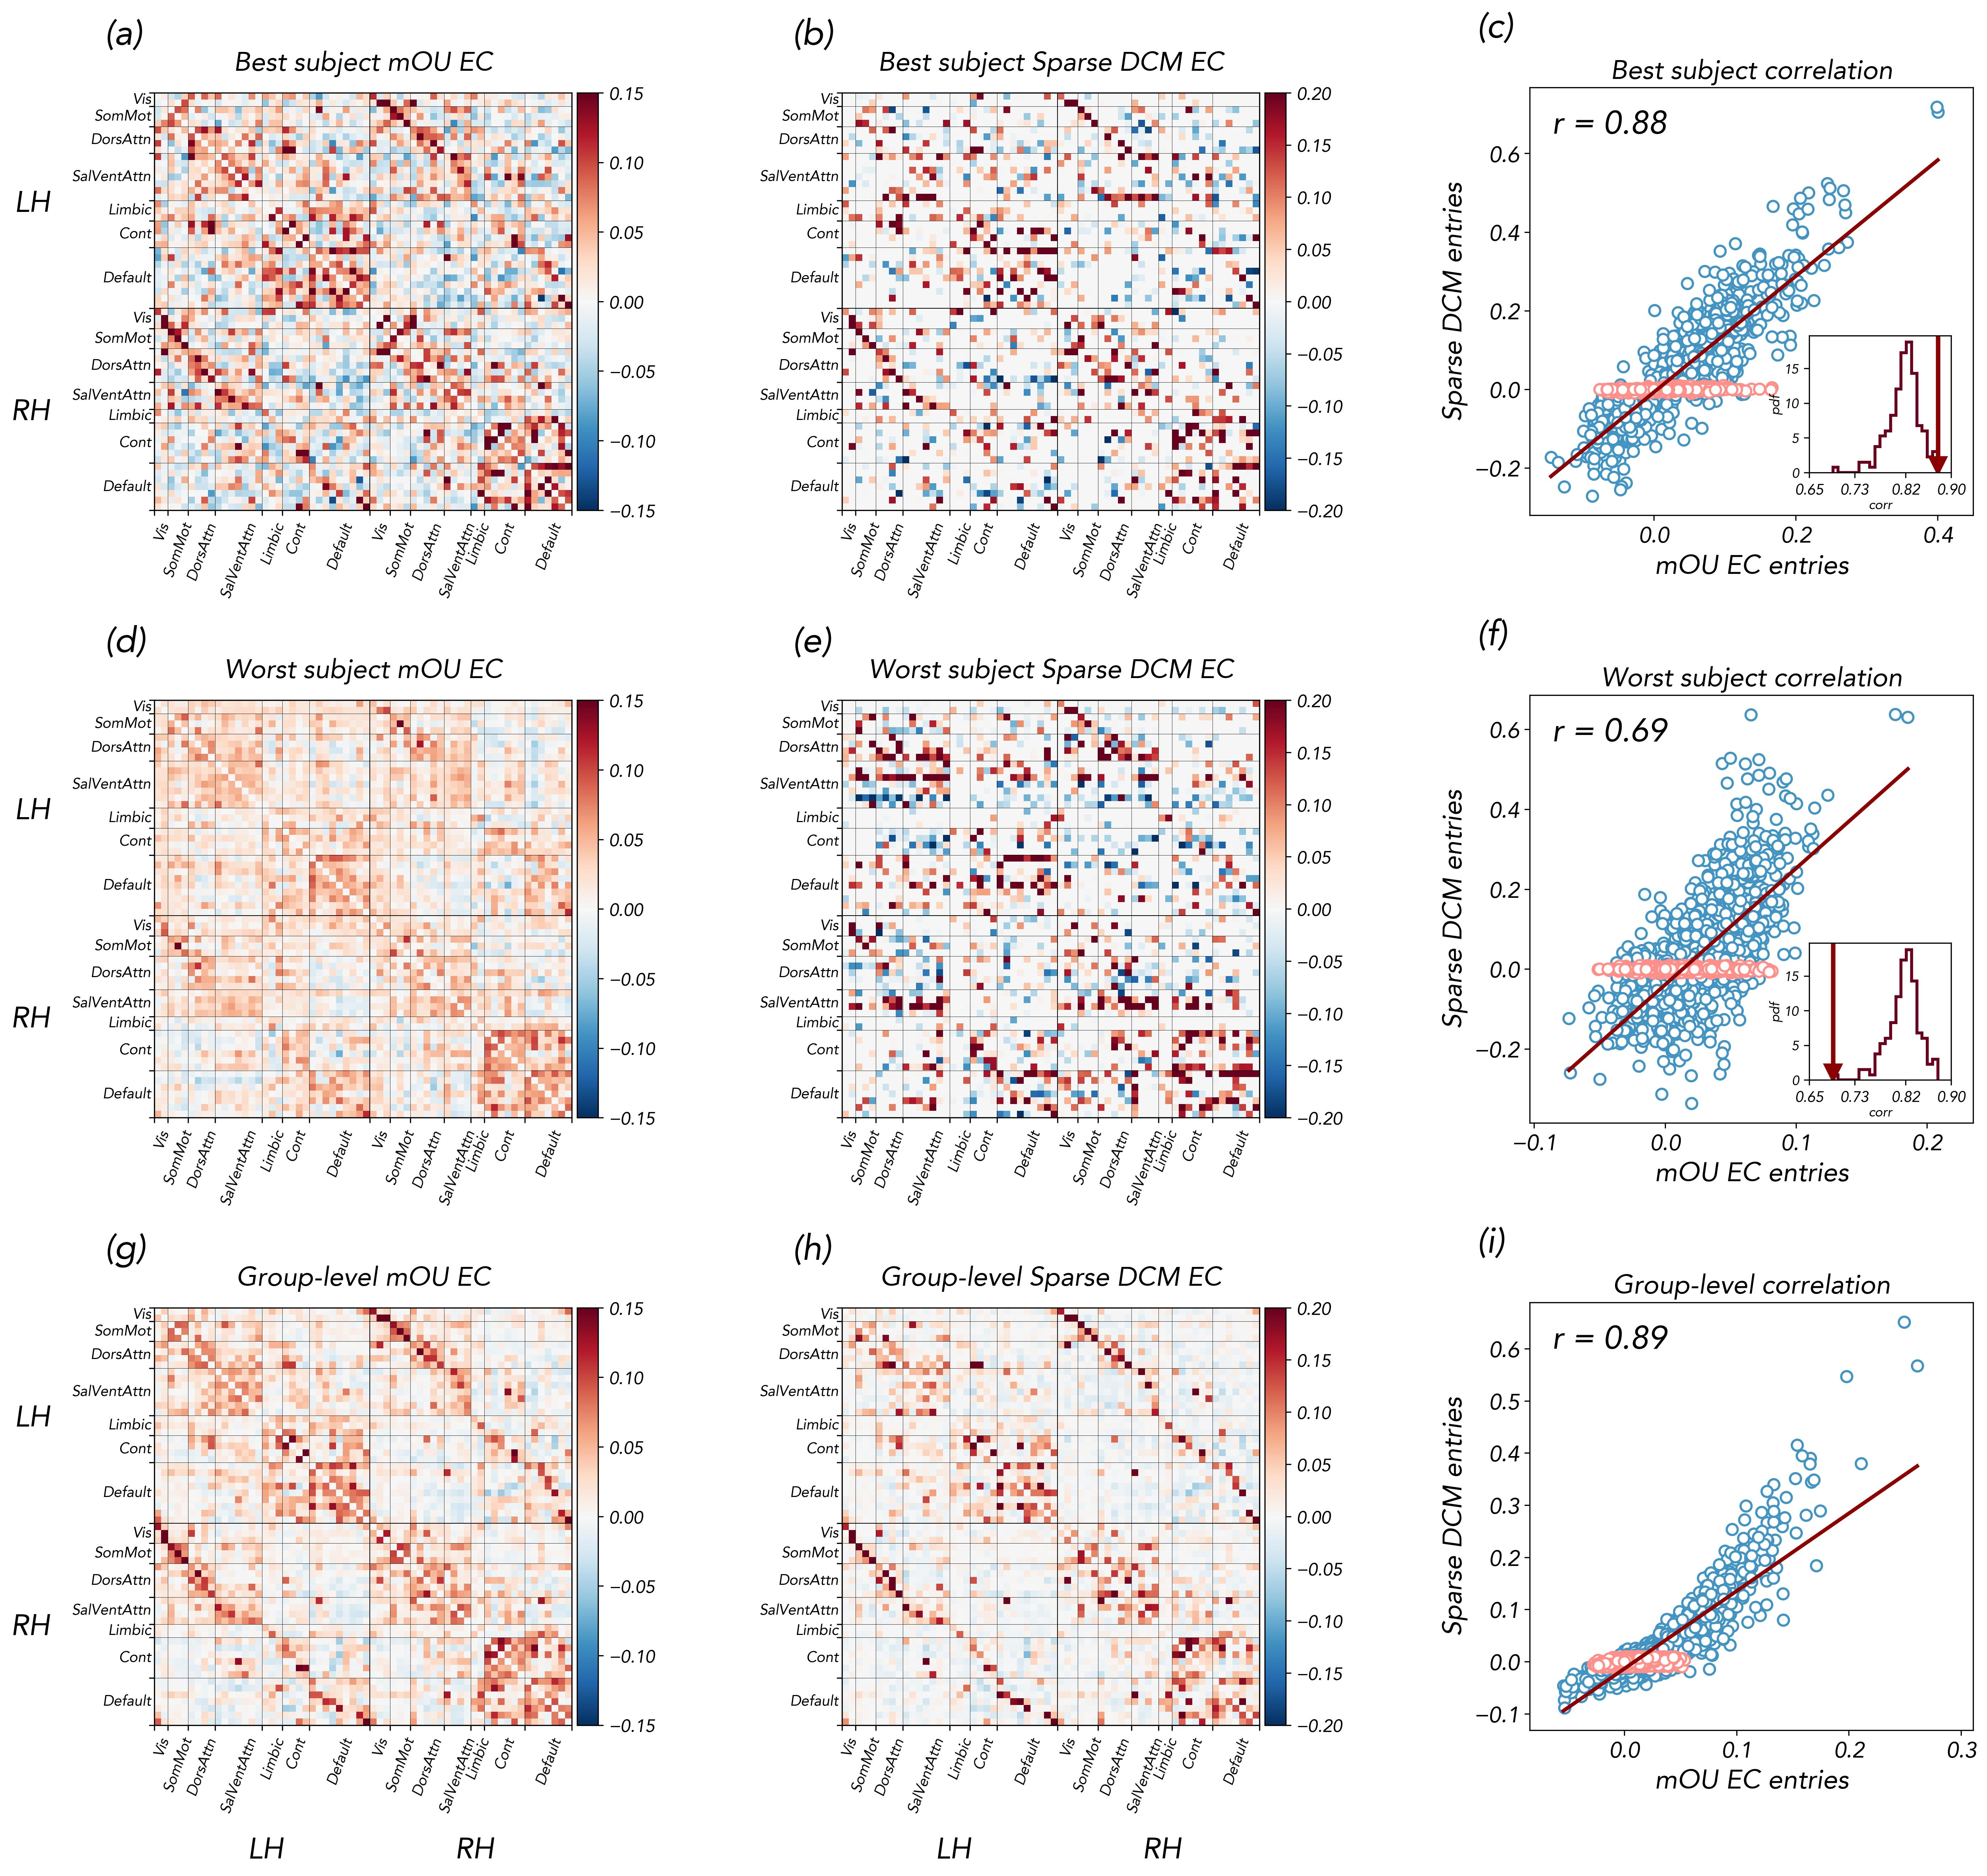

In [7]:
plt.rcParams['font.size'] = 8
from collections import OrderedDict
from scipy.stats import linregress
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import string
colors = cm.RdBu_r(np.linspace(0, 1, 10))
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
# Saved mOU matrices and explicitly matched indices were loaded above.
corrs = []
for i in range(ec_dcm.shape[0]):
    x = dediag(JS[indici][i, :62, :62])
    y = dediag(ec_dcm[i, :62, :62].T)
    mask = np.abs(y) < 0.01
    mask = np.logical_not(mask)
    r = np.corrcoef(x[mask].flatten(), y[mask].flatten())[0, 1]
    corrs.append(r)
corrs = np.asarray(corrs)
indeces = np.argsort(corrs)
best_idx = np.nanargmax(corrs)
worst_idx = np.nanargmin(corrs)
print(worst_idx)
worst_idx = indeces[0]
print(worst_idx)
print('BEST:', best_idx, round(corrs[best_idx], 2))
print('WORST:', worst_idx, round(corrs[worst_idx], 2))
xmin = 0.65
xmax = np.ceil(np.max(corrs) * 10) / 10
fig, axes = plt.subplots(3, 3, figsize=(22, 20))
v = [0.15, 0.2]
pos = 15

def plot_row(row_axes, js, title_prefix, plot_emi_x, group_level=False):
    titles = [f'{title_prefix} mOU EC', f'{title_prefix} Sparse DCM EC']
    for i, ax in enumerate(row_axes[:2]):
        if i == 0:
            plot_emi_y = True
        else:
            plot_emi_y = False
        im = plot_fc_matrix(js[i], new_lab, ax, cmap='RdBu_r', vmin=-v[i], vmax=v[i], fontsize=10, pos=pos, plot_emi_x=plot_emi_x, plot_emi_y=plot_emi_y)
        divider = make_axes_locatable(ax)
        cax = divider.append_axes('right', size='5%', pad=0.05)
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=12)
        ax.set_title(titles[i], pad=15, fontsize=18)
    ax = row_axes[2]
    x = dediag(js[0])
    y = dediag(js[1])
    mask = np.abs(y) < 0.01
    xnz = x[~mask]
    ynz = y[~mask]
    res = linregress(xnz.flatten(), ynz.flatten())
    slope = res.slope
    intercept = res.intercept
    r = res.rvalue
    ax.scatter(xnz, ynz, c='white', edgecolor='#4393c3', s=55, linewidth=1.5)
    ax.scatter(x[mask], y[mask], c='white', edgecolor='#ff8f8a', s=55, linewidth=1.5)
    xx = np.linspace(np.min(xnz), np.max(xnz), 200)
    yy = slope * xx + intercept
    ax.plot(xx, yy, linewidth=2.5, color='darkred')
    ax.set_xlim(np.min(xnz) - 0.03, np.max(xnz) + 0.05)
    ax.set_xlabel('mOU EC entries', fontsize=18)
    ax.set_ylabel('Sparse DCM entries', fontsize=18)
    ax.set_title(f'{title_prefix} correlation', fontsize=18)
    ax.tick_params(axis='both', labelsize=15)
    ax.text(0.05, 0.95, f'r = {r:.2f}', transform=ax.transAxes, verticalalignment='top', fontsize=22, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    if not group_level:
        axins = inset_axes(ax, width='32%', height='32%', loc='lower left', bbox_to_anchor=(0.63, 0.1, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
        axins.hist(corrs, bins=20, density=True, color='white', edgecolor=colors[-1], lw=2, histtype='step')
        axins.axvline(r, color='darkred', lw=3)
        axins.plot(r, 1, marker='v', color='darkred', ms=12)
        axins.set_xlim(xmin, xmax)
        axins.set_xticks(np.round(np.linspace(xmin, xmax, 4), 2))
        axins.tick_params(axis='x', labelsize=10)
        axins.tick_params(axis='y', labelsize=9)
        axins.set_xlabel('corr', fontsize=9, labelpad=1)
        axins.set_ylabel('pdf', fontsize=9, labelpad=1)
    return r
js_best = [dediag(JS[indici][best_idx, :62, :62]), dediag(ec_dcm[best_idx, :62, :62].T)]
plot_row(axes[0], js_best, 'Best subject', False)
js_worst = [dediag(JS[indici][worst_idx, :62, :62]), dediag(ec_dcm[worst_idx, :62, :62].T)]
plot_row(axes[1], js_worst, 'Worst subject', False)
js_group = [dediag(np.mean(JS[indici][:, :62, :62], 0)), dediag(np.mean(ec_dcm[:, :62, :62], 0).T)]
plot_row(axes[2], js_group, 'Group-level', True, True)
labels_panels = list(string.ascii_lowercase)
for ax, lab in zip(axes.flatten(), labels_panels):
    ax.text(-0.12, 1.18, f'({lab})', transform=ax.transAxes, fontsize=24, fontweight='bold', va='top', ha='left')
plt.subplots_adjust(hspace=0.42, wspace=0.55)
fig.savefig(OUTPUT / 'figure_2.jpg', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT / 'figure_2.pdf', bbox_inches='tight')
print('Best subject:', subject_ids[best_idx], 'r =', corrs[best_idx])
print('Worst subject:', subject_ids[worst_idx], 'r =', corrs[worst_idx])
print('Mean / 5th / 95th percentile:', np.mean(corrs), *np.percentile(corrs, [5, 95]))
print('Saved:', OUTPUT / 'figure_2.jpg')
plt.show()